# TP3 — Partie 2 : US Accidents avec Hadoop/HDFS et Spark
**Données : US Accidents (2016–2023), version 13, environ 7,7 millions d'accidents.**

**Question :** estimer la classe `Severity` d'un accident à partir de son contexte initial.
Cette étiquette décrit la **sévérité de l'impact sur la circulation**, sur quatre niveaux ; elle ne mesure pas les blessures.
Ce dataset ne contient que des accidents : il ne permet pas, seul, de calculer la probabilité qu'un accident survienne.

Architecture : CSV versionné → **HDFS/Parquet** → EDA distribuée → transformations Spark → Spark ML →
évaluation chronologique → sauvegarde du pipeline → **API FastAPI locale**.
HDFS fonctionne avec un NameNode et un DataNode sur cette machine ; Spark utilise deux threads locaux.
Il s'agit d'une architecture adaptée au passage en cluster, pas d'un benchmark multi-machines.

## 1. Préparation, configuration et acquisition
L'installation et le démarrage de HDFS sont décrits dans `README.md`. On ne reformate jamais le NameNode existant.
Le code réutilise le CSV local ou le télécharge avec `kagglehub` en version 13, puis enregistre son empreinte.
Le téléchargement initial a utilisé l'API officielle Kaggle ; les requêtes par plages n'ont modifié aucune ligne.

Nous évitons une seconde copie du CSV brut de 3 Go : Spark le lit localement et écrit directement le Parquet dans HDFS.
Le Parquet conserve les 46 colonnes sources, plus une année de partitionnement, avec compression Snappy.
Le CSV original est ensuite conservé en gzip sans perte pour économiser le disque ; il reste lisible directement par Spark.

In [1]:
from pathlib import Path
import sys,os,json,time,csv
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'tp3/common.py').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
os.environ['OMP_NUM_THREADS']='2'
os.environ['OPENBLAS_NUM_THREADS']='2'
import numpy as np
import pandas as pd
get_ipython().run_line_magic('matplotlib','inline')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display,Markdown
from pyspark.sql import functions as F,types as T
from pyspark import StorageLevel
from tp3.common import acquire,save_json,spark_session,local_uri,open_dataset,DATASETS
from tp3.accidents import NUMERIC,CATEGORICAL,RAW_FEATURES,engineer,spark_metrics
SEED=42
sns.set_theme(style='whitegrid',palette='colorblind')
HDFS_BASE=os.environ.get('TP3_HDFS_URI','hdfs://localhost:19000')+'/user/omar/tp3_us_accidents_v13'
RAW_PARQUET=HDFS_BASE+'/raw_parquet'
FEATURE_PARQUET=HDFS_BASE+'/features_parquet'
print('Projet :',ROOT)

Projet : /home/omar/Bureau/5A/big data/TP 3


In [2]:
path=acquire('accidents')
print(f"CSV décompressé : {DATASETS['accidents']['bytes']/1e9:.3f} Go ; stockage local : {path.stat().st_size/1e9:.3f} Go")
spark=spark_session()
print('Spark :',spark.version,'; mode :',spark.sparkContext.master)
print('HDFS :',spark.sparkContext._jsc.hadoopConfiguration().get('fs.defaultFS'))
fs=spark._jvm.org.apache.hadoop.fs.FileSystem.get(spark._jsc.hadoopConfiguration())
assert fs.getUri().getScheme()=='hdfs','Cette partie exige un vrai stockage HDFS.'

def hdfs_exists(uri):
    return fs.exists(spark._jvm.org.apache.hadoop.fs.Path(uri+'/_SUCCESS'))

def hdfs_size(uri):
    return fs.getContentSummary(spark._jvm.org.apache.hadoop.fs.Path(uri)).getLength()

CSV décompressé : 3.058 Go ; stockage local : 0.835 Go


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/12 16:11:11 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/12 16:11:11 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


26/11/12 16:11:12 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


Spark : 4.2.0 ; mode : local[2]
HDFS : hdfs://localhost:19000


## 2. Ingestion et choix de stockage
Schéma explicite de chaînes pour préserver la source : les conversions sont ensuite contrôlées.
Le mode `FAILFAST` signale les lignes CSV mal formées. Les guillemets sont gérés par le lecteur Spark.
Partitionner par année facilite les lectures temporelles. `coalesce(8)` limite les fichiers sans redistribuer toutes les lignes par un shuffle. Nous bornons le parallélisme pour limiter RAM et fichiers temporaires.
Les écritures sont limitées au répertoire dédié de ce TP ; une ingestion déjà achevée est réutilisée.

In [3]:
with open_dataset(path) as handle:
    columns=next(csv.reader(handle))
assert len(columns)==46
schema=T.StructType([T.StructField(c,T.StringType(),True) for c in columns])
begin=time.perf_counter()
if not hdfs_exists(RAW_PARQUET):
    raw_csv=(spark.read.schema(schema).option('header',True).option('escape','"')
             .option('mode','FAILFAST').csv(local_uri(path)))
    raw_csv=(raw_csv.withColumn('year',F.year(F.expr('try_cast(Start_Time as timestamp)'))))
    raw_csv.coalesce(8).write.mode('overwrite').partitionBy('year').parquet(RAW_PARQUET)
    ingestion_seconds=time.perf_counter()-begin
    save_json({'seconds':ingestion_seconds,'csv_bytes':DATASETS['accidents']['bytes'],'parquet_bytes':hdfs_size(RAW_PARQUET)},ROOT/'reports/accidents_ingestion.json')
else:
    print('Parquet existant réutilisé ; pas de nouvelle mesure du temps initial.')
raw=spark.read.parquet(RAW_PARQUET)
n_raw=raw.count()
print('Lignes :',f'{n_raw:,}','; colonnes sources :',len(columns),' ; partitions lues :',raw.rdd.getNumPartitions())
print('Parquet HDFS :',round(hdfs_size(RAW_PARQUET)/1e6,1),'Mo')
raw.select('ID','Severity','Start_Time','State','Weather_Condition').show(5,truncate=False)
assert n_raw==7728394, 'Le contenu ne correspond pas à la version 13 documentée.'

Parquet existant réutilisé ; pas de nouvelle mesure du temps initial.


Lignes : 7,728,394 ; colonnes sources : 46  ; partitions lues : 10
Parquet HDFS : 805.4 Mo


+---------+--------+-------------------+-----+-----------------+
|ID       |Severity|Start_Time         |State|Weather_Condition|
+---------+--------+-------------------+-----+-----------------+
|A-3933978|2       |2022-02-17 06:39:30|CA   |Fair             |
|A-4322186|2       |2022-07-24 17:47:16|KS   |Cloudy           |
|A-3933979|2       |2022-12-22 07:37:38|MD   |Snow             |
|A-4322188|2       |2022-07-29 06:37:02|NY   |Partly Cloudy    |
|A-3933980|2       |2022-03-09 08:30:00|CA   |Fair             |
+---------+--------+-------------------+-----+-----------------+
only showing top 5 rows


## 3. EDA sur la totalité du dataset
Toutes les agrégations sont exécutées dans Spark. Seuls de petits résultats agrégés sont convertis en pandas pour les figures.
Aucun `toPandas()` ou `collect()` ne rapatrie les millions de lignes brutes.
Nous examinons la couverture temporelle, géographique, le déséquilibre des classes et les valeurs manquantes.

In [4]:
counts=raw.agg(F.count('*').alias('rows'),F.countDistinct('ID').alias('unique_ids'),
              F.sum(F.col('ID').isNull().cast('int')).alias('missing_ids')).first().asDict()
print(counts)
null_counts=raw.agg(*[F.sum((F.col(c).isNull() | (F.trim(F.col(c))=='')).cast('long')).alias(c) for c in columns]).first().asDict()
nulls=pd.DataFrame([{'colonne':c,'manquants':v or 0,'pct':100*(v or 0)/n_raw} for c,v in null_counts.items()]).sort_values('pct',ascending=False)
display(nulls.head(18).round(2))
nulls.to_csv(ROOT/'reports/accidents_missing.csv',index=False)
by_year=raw.groupBy('year').count().orderBy('year').toPandas()
by_class=raw.groupBy('Severity').count().orderBy('Severity').toPandas()
by_state=raw.groupBy('State').count().orderBy(F.desc('count')).limit(15).toPandas()
display(by_class.assign(proportion=by_class['count']/n_raw))

{'rows': 7728394, 'unique_ids': 7728394, 'missing_ids': 0}


,colonne,manquants,pct
8,End_Lng,3402762,44.03
7,End_Lat,3402762,44.03
27,Precipitation(in),2203586,28.51
21,Wind_Chill(F),1999019,25.87
26,Wind_Speed(mph),571233,7.39
24,Visibility(mi),177098,2.29
25,Wind_Direction,175206,2.27
22,Humidity(%),174144,2.25
28,Weather_Condition,173459,2.24
20,Temperature(F),163853,2.12


/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,Severity,count,proportion
0,1,67366,0.008717
1,2,6156981,0.796670
2,3,1299337,0.168125
3,4,204710,0.026488


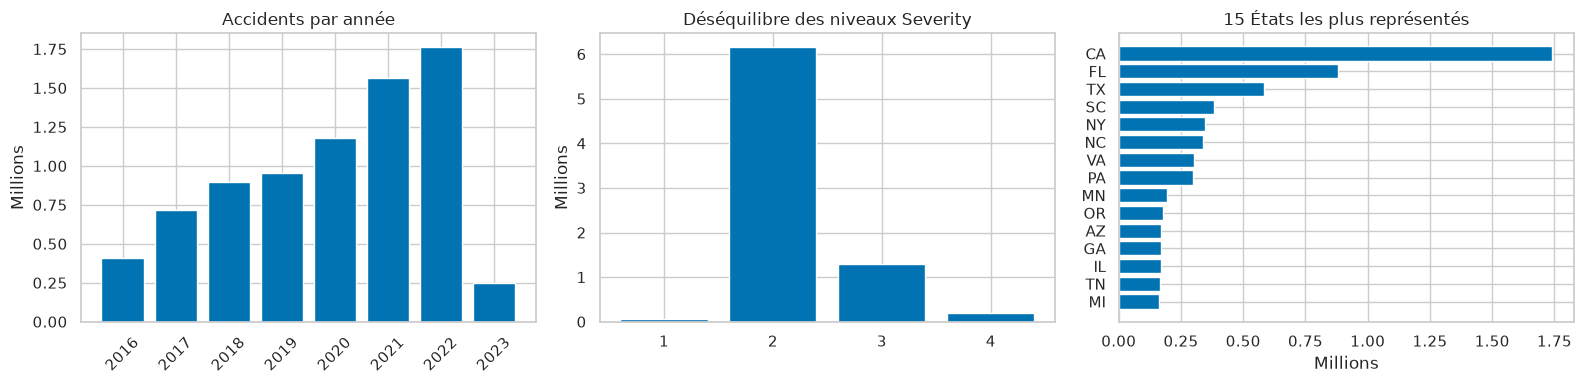

In [5]:
fig,axes=plt.subplots(1,3,figsize=(16,4))
axes[0].bar(by_year['year'].astype(str),by_year['count']/1e6);axes[0].set(title='Accidents par année',ylabel='Millions');axes[0].tick_params(axis='x',rotation=45)
axes[1].bar(by_class['Severity'],by_class['count']/1e6);axes[1].set(title='Déséquilibre des niveaux Severity',ylabel='Millions')
axes[2].barh(by_state['State'][::-1],by_state['count'][::-1]/1e6);axes[2].set(title='15 États les plus représentés',xlabel='Millions')
plt.tight_layout();plt.show()

### Lecture critique
Les fréquences reflètent à la fois le trafic, les accidents et la couverture des fournisseurs. Elles ne sont pas
normalisées par population ou kilomètres parcourus et ne permettent pas de classer le « danger » des États.
2023 n'est couvert que jusqu'en mars : comparer son total à une année entière serait trompeur.
Le déséquilibre justifie une référence majoritaire et une mesure **macro-F1**, plutôt que l'accuracy seule.

/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


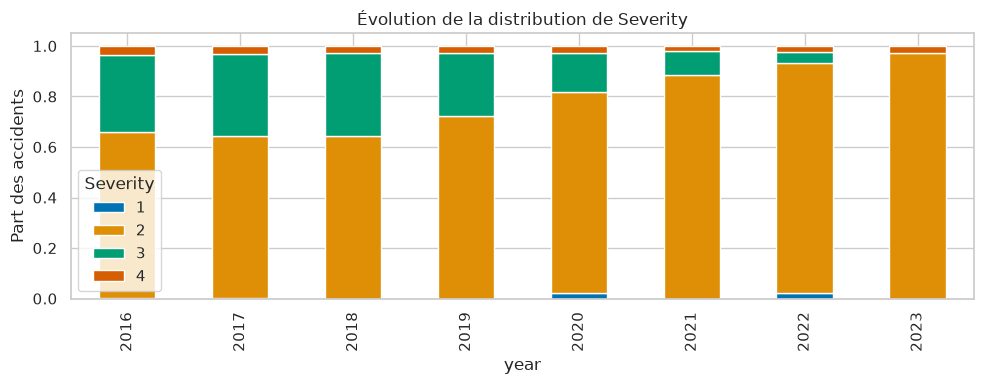

In [6]:
# Spark SQL : proportion des classes par année, utile pour voir les changements de distribution.
raw.createOrReplaceTempView('accidents_source')
annual=spark.sql("""
SELECT year, Severity, COUNT(*) AS n
FROM accidents_source GROUP BY year, Severity ORDER BY year, Severity
""").toPandas()
annual['share']=annual['n']/annual.groupby('year')['n'].transform('sum')
annual.pivot(index='year',columns='Severity',values='share').plot(kind='bar',stacked=True,figsize=(10,4))
plt.ylabel('Part des accidents');plt.title('Évolution de la distribution de Severity');plt.tight_layout();plt.show()
annual.to_csv(ROOT/'reports/accidents_distribution_year.csv',index=False)

## 4. Prétraitement, disponibilité temporelle et variables
`ID` sert à dédupliquer et à échantillonner, jamais à prédire. `Severity - 1` donne les labels Spark 0 à 3.
Les événements sans ID, date exploitable ou classe valide sont exclus. Les variables numériques hors domaine
physique deviennent manquantes ; aucune valeur n'est remplacée arbitrairement par zéro.

**Fuites évitées :** `End_Time`, la durée, `End_Lat/End_Lng`, `Distance(mi)` et `Description` décrivent l'issue ou
l'étendue de l'événement. `Source` pourrait révéler les pratiques d'étiquetage du fournisseur. Ces champs sont exclus.

**Météo :** une mesure postérieure à l'accident ne serait pas disponible au début. Nous masquons donc les variables
météo si `Weather_Timestamp` est manquant, ultérieur à `Start_Time`, ou vieux de plus de deux heures.
Les horodatages source sont traités comme des heures locales comparables à l'intérieur d'un événement.

**Transformations déterministes :** heure/jour/mois en sin/cos (continuité cyclique), regroupement des descriptions
météo, booléens en 0/1. Les médianes et encodages seront appris après le split.

In [7]:
import inspect
print(inspect.getsource(engineer))
wt=F.expr('try_cast(Weather_Timestamp as timestamp)')
st=F.expr('try_cast(Start_Time as timestamp)')
weather_audit=raw.agg(F.sum((wt>st).cast('long')).alias('weather_after_start'),
                    F.sum((wt.isNull() | (wt>st) | (wt<st-F.expr('INTERVAL 2 HOURS'))).cast('long')).alias('weather_masked')).first().asDict()
print('Audit disponibilité météo :',weather_audit)

def engineer(df):
    from pyspark.sql import functions as F
    import math
    df = df.withColumn('_time', F.expr('try_cast(Start_Time as timestamp)'))
    df = df.withColumn('_weather_time', F.expr('try_cast(Weather_Timestamp as timestamp)'))
    weather_ok = (F.col('_weather_time') <= F.col('_time')) & (F.col('_weather_time') >= F.col('_time') - F.expr('INTERVAL 2 HOURS'))
    for name in ['Temperature(F)','Humidity(%)','Pressure(in)','Visibility(mi)',
                 'Wind_Speed(mph)','Precipitation(in)','Weather_Condition']:
        df = df.withColumn(name, F.when(weather_ok, F.col(name)))
    for old, new in RAW_NUMERIC.items():
        df = df.withColumn(new, F.expr(f'try_cast(`{old}` as double)'))
    # Valeurs hors domaine physique représentées comme manquantes (règles fixes).
    bounds = {'Start_Lat':(-90,90),'Start_Lng':(-180,180),'Temperature_F':(-100,150),
              'Humidity_pct':(0,100),'Pressure_in':(20,35),'Visibility_mi':(0,200),
              'Wind_Speed_mph':

Audit disponibilité météo : {'weather_after_start': 3787674, 'weather_masked': 3933101}


In [8]:
if not hdfs_exists(FEATURE_PARQUET):
    base=raw.withColumn('label',F.expr('try_cast(Severity as double)')-1)
    base=base.filter(F.col('ID').isNotNull() & F.col('label').isin(0.,1.,2.,3.) & st.isNotNull())
    # Pas de coût de shuffle inutile lorsque l'audit prouve l'unicité des identifiants.
    if counts['unique_ids'] != counts['rows']:
        base=base.dropDuplicates(['ID'])
    transformed=engineer(base).select('ID','label','year',*NUMERIC,*CATEGORICAL)
    transformed.coalesce(8).write.mode('overwrite').partitionBy('year').parquet(FEATURE_PARQUET)
features=spark.read.parquet(FEATURE_PARQUET)
n_clean=features.count()
print('Événements retenus :',f'{n_clean:,}','; exclus :',n_raw-n_clean)
print('Parquet des variables :',round(hdfs_size(FEATURE_PARQUET)/1e6,1),'Mo')
save_json({'raw_rows':n_raw,'eligible_rows':n_clean,'id_audit':counts,'weather':weather_audit},ROOT/'reports/accidents_quality.json')

Événements retenus : 7,728,394 ; exclus : 0
Parquet des variables : 202.4 Mo


## 5. Protocole chronologique et coût de calcul
- **Train : 2016–2020**, échantillon déterministe de **5 %**, uniforme par hachage d'ID ; toutes les classes sont conservées.
- **Validation : 2021 entière**, utilisée pour choisir le modèle et sa configuration.
- **Test : 2022–mars 2023 entier**, réservé à l'évaluation finale.

L'EDA, les contrôles et les transformations portent sur la totalité des données. Seul l'ajustement des modèles est
échantillonné, pour un TP reproductible sur 16 Go de RAM. La validation et le test gardent leur distribution réelle.
`TRAIN_FRACTION=1.0` permet l'apprentissage complet avec davantage de ressources. Cela relance les ajustements,
mais ne demande pas de réingérer les données. Les poids de classes proviennent uniquement du train utilisé.

In [9]:
TRAIN_FRACTION=float(os.environ.get('TP3_TRAIN_FRACTION','0.05'))
assert 0 < TRAIN_FRACTION <= 1
bucket=F.pmod(F.xxhash64('ID',F.lit(SEED)),F.lit(10000))
sample_condition=bucket < int(TRAIN_FRACTION*10000)
train_all=features.filter(F.col('year')<=2020)
valid=features.filter(F.col('year')==2021)
test=features.filter(F.col('year')>=2022)
train=train_all.filter(sample_condition).persist(StorageLevel.DISK_ONLY)
train_counts=train.groupBy('label').count().orderBy('label').toPandas()
assert len(train_counts)==4 and train_counts['count'].min()>0
split_counts=features.withColumn('split',F.when(F.col('year')<=2020,'train_pool').when(F.col('year')==2021,'validation').otherwise('test')).groupBy('split').count().toPandas()
display(split_counts)
display(train_counts.assign(Severity=train_counts['label']+1))
print('Fraction train :',TRAIN_FRACTION,'; lignes ajustement :',int(train_counts['count'].sum()))
split_counts.to_csv(ROOT/'reports/accidents_splits.csv',index=False)
non_null=train.agg(*[F.count(c).alias(c) for c in NUMERIC]).first().asDict()
assert all(v>0 for v in non_null.values()),'Une variable entièrement manquante nécessite une revue.'

/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


,split,count
0,test,2009085
1,validation,1563753
2,train_pool,4155556


,label,count,Severity
0,0.0,1444,1.0
1,1.0,146530,2.0
2,2.0,53634,3.0
3,3.0,6123,4.0


Fraction train : 0.05 ; lignes ajustement : 207731


## 6. Pipeline Spark ML et pondération
Le pipeline contient `Imputer` (médiane), `StringIndexer` (catégories inconnues conservées), `OneHotEncoder`,
`VectorAssembler`, `StandardScaler` et le classifieur. Les indexeurs et médianes sont ajustés sur le train seulement.
Les transformations déterministes précédentes sont partagées avec l'API via `tp3.accidents.engineer`.

On compare une régression logistique multinomiale et deux profondeurs de Random Forest. Les poids
`n / (4 × n_classe)` donnent le même poids total aux quatre classes en version complète. Nous testons également
l'exposant 1/2 et 1/4, avec moyenne des poids égale à 1, pour réduire le sur-apprentissage des classes rares.
Le macro-F1 sera lu avec le rappel par classe et l'accuracy.
L'évaluation reste **non pondérée**, sur la distribution réelle. Les sorties probabilistes du modèle pondéré
ne sont pas présentées comme des probabilités calibrées de la population.

In [10]:
from pyspark.ml import Pipeline,PipelineModel
from pyspark.ml.feature import Imputer,StringIndexer,OneHotEncoder,VectorAssembler,StandardScaler
from pyspark.ml.classification import LogisticRegression,RandomForestClassifier

def with_weights(frame,power=1.0):
    frequencies={int(r['label']):int(r['count']) for r in frame.groupBy('label').count().collect()}
    assert set(frequencies)=={0,1,2,3}
    n=sum(frequencies.values())
    raw_weights={k:(n/(4*v))**power for k,v in frequencies.items()}
    normalization=n/sum(frequencies[k]*v for k,v in raw_weights.items())
    weights={k:v*normalization for k,v in raw_weights.items()}
    expr=F.create_map(*[x for k,v in weights.items() for x in (F.lit(float(k)),F.lit(float(v)))])
    return frame.withColumn('_weight',expr[F.col('label')]),weights

def pipeline_for(classifier):
    imputed=['imputed_'+c for c in NUMERIC]
    indexed=[c+'_index' for c in CATEGORICAL]
    encoded=[c+'_vector' for c in CATEGORICAL]
    stages=[Imputer(inputCols=NUMERIC,outputCols=imputed,strategy='median',relativeError=.001),
            StringIndexer(inputCols=CATEGORICAL,outputCols=indexed,handleInvalid='keep'),
            OneHotEncoder(inputCols=indexed,outputCols=encoded,handleInvalid='keep',dropLast=False),
            VectorAssembler(inputCols=imputed+encoded,outputCol='assembled'),
            StandardScaler(inputCol='assembled',outputCol='features',withMean=False,withStd=True),classifier]
    return Pipeline(stages=stages)
weighted_train,weights=with_weights(train,power=1.0)
print('Poids inverses normalisés, ajustés sur le train :',weights)
weight_powers={'Régression logistique pondérée':1.0,
               'Régression logistique — pondération modérée':0.5,
               'Régression logistique — pondération légère':0.25,
               'Random Forest — pondération modérée':0.5,
               'Random Forest profondeur 6':1.0,
               'Random Forest profondeur 10':1.0}
classifiers={
    'Régression logistique pondérée':LogisticRegression(maxIter=40,regParam=.05,elasticNetParam=0.,family='multinomial',weightCol='_weight'),
    'Régression logistique — pondération modérée':LogisticRegression(maxIter=40,regParam=.05,elasticNetParam=0.,family='multinomial',weightCol='_weight'),
    'Régression logistique — pondération légère':LogisticRegression(maxIter=40,regParam=.05,elasticNetParam=0.,family='multinomial',weightCol='_weight'),
    'Random Forest — pondération modérée':RandomForestClassifier(numTrees=40,maxDepth=10,maxBins=32,subsamplingRate=.8,weightCol='_weight',seed=SEED),
    'Random Forest profondeur 6':RandomForestClassifier(numTrees=40,maxDepth=6,maxBins=32,subsamplingRate=.8,weightCol='_weight',seed=SEED),
    'Random Forest profondeur 10':RandomForestClassifier(numTrees=40,maxDepth=10,maxBins=32,subsamplingRate=.8,weightCol='_weight',seed=SEED),
}

Poids inverses normalisés, ajustés sur le train : {1: 0.3544171841943629, 0: 35.96450831024931, 3: 8.481585823942511, 2: 0.9682803818473357}


## 7. Sélection sur validation
Le **macro-F1** est la moyenne des F1 des quatre classes, en traitant une classe absente/prédite jamais comme zéro.
Spark nomme `f1` sa métrique **pondérée par le support** : ce n'est pas le macro-F1. Pour éviter cette confusion,
notre fonction calcule exactement les métriques depuis les 16 cases de la matrice de confusion agrégée dans Spark.
La classe majoritaire est déterminée uniquement à partir du train.

In [11]:
majority=float(train_counts.loc[train_counts['count'].idxmax(),'label'])
validation_rows=[]
majority_metrics,_,_=spark_metrics(valid.select('label').withColumn('prediction',F.lit(majority)))
validation_rows.append({'modèle':'Classe majoritaire',**majority_metrics,'fit_seconds':0.,'eval_seconds':0.})
fitted={}
for name,classifier in classifiers.items():
    begin=time.perf_counter()
    weighted_candidate,candidate_weights=with_weights(train,power=weight_powers[name])
    model=pipeline_for(classifier).fit(weighted_candidate)
    fit_seconds=time.perf_counter()-begin
    begin=time.perf_counter()
    metrics,_,_=spark_metrics(model.transform(valid))
    validation_rows.append({'modèle':name,**metrics,'fit_seconds':fit_seconds,'eval_seconds':time.perf_counter()-begin})
    fitted[name]=model
    print(name,metrics,flush=True)
validation=pd.DataFrame(validation_rows).sort_values('macro_f1',ascending=False).reset_index(drop=True)
display(validation.round(4))
validation.to_csv(ROOT/'reports/accidents_validation.csv',index=False)
# La baseline sert de garde-fou ; le meilleur pipeline ML est choisi pour le service et son utilité est explicitement comparée.
best_name=validation.loc[validation['modèle']!='Classe majoritaire'].iloc[0]['modèle']
print('Pipeline ML retenu :',best_name)
if validation.iloc[0]['modèle']=='Classe majoritaire':
    print('Attention : aucun modèle ML ne dépasse la référence sur validation. Déploiement pédagogique uniquement.')

Régression logistique pondérée {'macro_f1': 0.19770148226918816, 'accuracy': 0.3571913211357548, 'balanced_accuracy': 0.3522572345145565, 'weighted_f1': 0.4734358417954938, 'n': 1563753}


Régression logistique — pondération modérée {'macro_f1': 0.2955862921204189, 'accuracy': 0.7676909332867786, 'balanced_accuracy': 0.31402602050448114, 'weighted_f1': 0.7929208352523164, 'n': 1563753}


Régression logistique — pondération légère {'macro_f1': 0.2904034229566538, 'accuracy': 0.8406238069567252, 'balanced_accuracy': 0.2915837993613444, 'weighted_f1': 0.8313984229845706, 'n': 1563753}


Random Forest — pondération modérée {'macro_f1': 0.28367659320793115, 'accuracy': 0.8365227756557462, 'balanced_accuracy': 0.2855786452223166, 'weighted_f1': 0.8275890467645193, 'n': 1563753}


Random Forest profondeur 6 {'macro_f1': 0.17281650529093415, 'accuracy': 0.3149666219665126, 'balanced_accuracy': 0.31666080704043964, 'weighted_f1': 0.43615799141356454, 'n': 1563753}


Random Forest profondeur 10 {'macro_f1': 0.1931498982477233, 'accuracy': 0.3574848457524942, 'balanced_accuracy': 0.3484305517088785, 'weighted_f1': 0.47410887160516824, 'n': 1563753}


,modèle,macro_f1,accuracy,balanced_accuracy,weighted_f1,n,fit_seconds,eval_seconds
0,Régression logistique — pondération modérée,0.2956,0.7677,0.3140,0.7929,1563753,7.4025,3.1267
1,Régression logistique — pondération légère,0.2904,0.8406,0.2916,0.8314,1563753,6.9159,3.5801
2,Random Forest — pondération modérée,0.2837,0.8365,0.2856,0.8276,1563753,16.3282,12.4577
3,Classe majoritaire,0.2348,0.8855,0.2500,0.8317,1563753,0.0000,0.0000
4,Régression logistique pondérée,0.1977,0.3572,0.3523,0.4734,1563753,11.6319,4.5848
5,Random Forest profondeur 10,0.1931,0.3575,0.3484,0.4741,1563753,13.7487,13.1465
6,Random Forest profondeur 6,0.1728,0.3150,0.3167,0.4362,1563753,8.4104,8.8744


Pipeline ML retenu : Régression logistique — pondération modérée


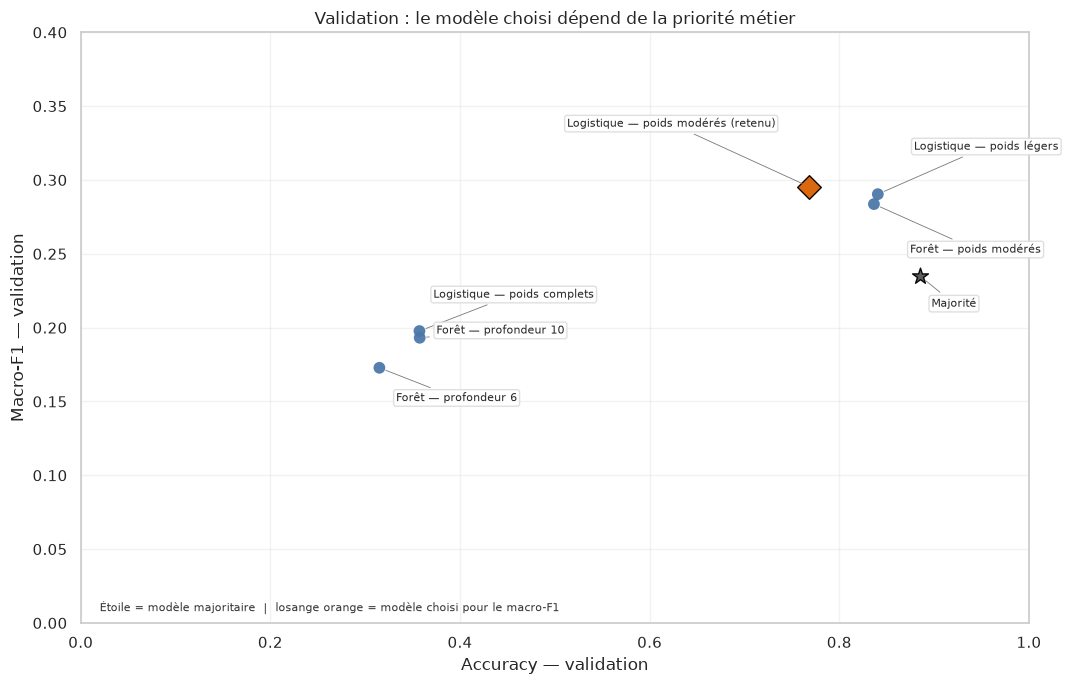

In [12]:
fig,ax=plt.subplots(figsize=(11,7))
offsets={
    'Classe majoritaire':(8,-22),
    'Régression logistique pondérée':(10,24),
    'Random Forest profondeur 10':(12,3),
    'Random Forest profondeur 6':(12,-24),
    'Régression logistique — pondération modérée':(-24,43),
    'Régression logistique — pondération légère':(26,32),
    'Random Forest — pondération modérée':(26,-35),
}
short_names={
    'Classe majoritaire':'Majorité',
    'Régression logistique pondérée':'Logistique — poids complets',
    'Régression logistique — pondération modérée':'Logistique — poids modérés (retenu)',
    'Régression logistique — pondération légère':'Logistique — poids légers',
    'Random Forest — pondération modérée':'Forêt — poids modérés',
    'Random Forest profondeur 6':'Forêt — profondeur 6',
    'Random Forest profondeur 10':'Forêt — profondeur 10',
}
for _,row in validation.iterrows():
    name=row['modèle'];baseline=name=='Classe majoritaire';chosen=name==best_name
    offset=offsets[name]
    ax.scatter(row['accuracy'],row['macro_f1'],s=145 if (baseline or chosen) else 72,
               marker='*' if baseline else ('D' if chosen else 'o'),
               color='#d95f02' if chosen else ('#555555' if baseline else '#4c78a8'),
               edgecolor='black' if baseline or chosen else 'none',alpha=.95,zorder=3)
    ax.annotate(short_names[name],(row['accuracy'],row['macro_f1']),xytext=offset,textcoords='offset points',
                fontsize=8,ha='left' if offset[0]>=0 else 'right',
                arrowprops={'arrowstyle':'-','color':'#777777','lw':.6,'shrinkA':3,'shrinkB':5},
                bbox={'boxstyle':'round,pad=.22','fc':'white','ec':'#dddddd','alpha':.92})
ax.set(xlabel='Accuracy — validation',ylabel='Macro-F1 — validation',
       title='Validation : le modèle choisi dépend de la priorité métier')
ax.set_xlim(0,1);ax.set_ylim(0,max(.4,float(validation['macro_f1'].max())+.09))
ax.grid(alpha=.25)
ax.text(.02,.02,'Étoile = modèle majoritaire  |  losange orange = modèle choisi pour le macro-F1',
        transform=ax.transAxes,fontsize=8,color='#333333')
plt.tight_layout();plt.show()

### Le compromis apparaît sur le graphique
Le coin inférieur droit favorise l'accuracy et la classe fréquente ; le coin supérieur favorise le macro-F1 des quatre classes.
Le modèle déployé suit le second critère. On ne peut pas cacher la baisse de précision générale derrière une seule métrique.

## 8. Modèle final et test temporel intact
Le meilleur pipeline est réajusté sur le même échantillonnage de **2016–2021** (train + validation).
Les médianes, catégories et poids sont alors réappris sur cet ensemble. Aucun événement de 2022–2023 n'est utilisé.
Le test mesure notamment l'effet des changements de distribution dans le temps.

In [13]:
train.unpersist()
fit_data=features.filter(F.col('year')<=2021).filter(sample_condition).persist(StorageLevel.DISK_ONLY)
selected_power=weight_powers[best_name]
weighted_fit,final_weights=with_weights(fit_data,power=selected_power)
fit_rows=fit_data.count()
begin=time.perf_counter()
final_model=pipeline_for(classifiers[best_name].copy({})).fit(weighted_fit)
final_fit_seconds=time.perf_counter()-begin
print('Modèle final ajusté sur',fit_rows,'lignes en',round(final_fit_seconds,1),'s')
predictions=final_model.transform(test).select('ID','year','label','prediction','probability').persist(StorageLevel.DISK_ONLY)
begin=time.perf_counter()
test_metrics,class_report,cm=spark_metrics(predictions)
print('Temps évaluation finale :',round(time.perf_counter()-begin,1),'s')
display(pd.DataFrame([test_metrics]).round(4))
display(class_report.round(4))
final_majority=float(fit_data.groupBy('label').count().orderBy(F.desc('count')).first()['label'])
baseline_test,_,_=spark_metrics(test.select('label').withColumn('prediction',F.lit(final_majority)))
display(pd.DataFrame([{'modèle':best_name,**test_metrics},{'modèle':'Classe majoritaire',**baseline_test}]).round(4))
save_json({'model':best_name,'test':test_metrics,'baseline_test':baseline_test,'fit_rows':fit_rows,
           'fit_seconds':final_fit_seconds,'train_fraction':TRAIN_FRACTION},ROOT/'reports/accidents_test.json')
class_report.to_csv(ROOT/'reports/accidents_test_by_class.csv',index=False)

Modèle final ajusté sur 285995 lignes en 10.6 s


Temps évaluation finale : 7.0 s


,macro_f1,accuracy,balanced_accuracy,weighted_f1,n
0,0.2749,0.8199,0.3054,0.8353,2009085


,Severity,precision,recall,f1,support
0,1,0.0377,0.0045,0.0080,37875
1,2,0.9275,0.8798,0.9030,1842918
2,3,0.1005,0.3148,0.1524,77957
3,4,0.0930,0.0225,0.0362,50335


,modèle,macro_f1,accuracy,balanced_accuracy,weighted_f1,n
0,Régression logistique — pondération modérée,0.2749,0.8199,0.3054,0.8353,2009085
1,Classe majoritaire,0.2392,0.9173,0.2500,0.8777,2009085


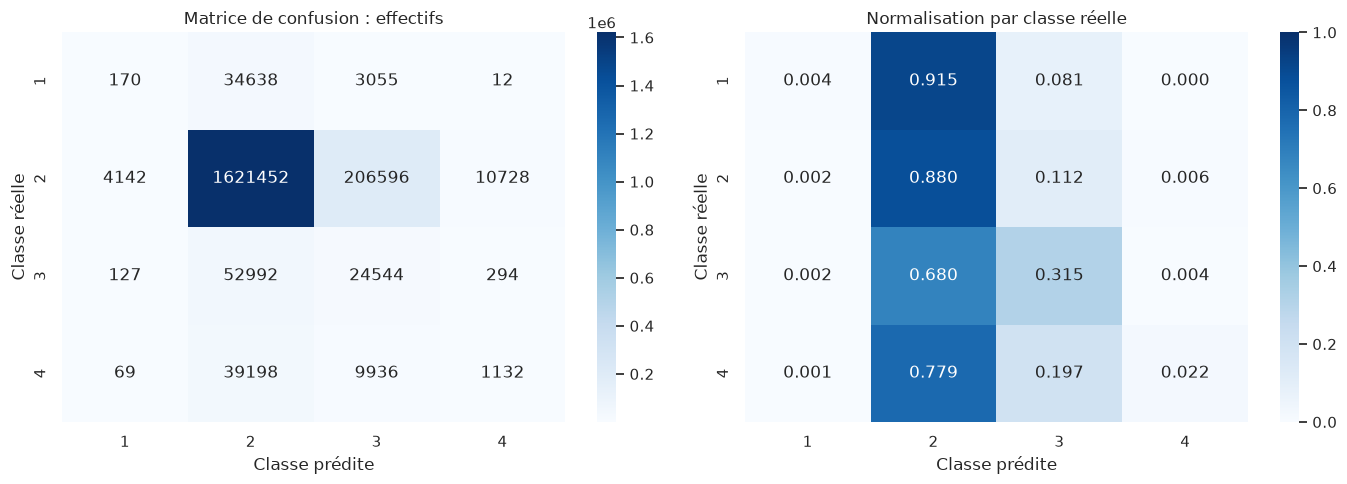

,year,macro_f1,accuracy,balanced_accuracy,weighted_f1,n
0,2022,0.2773,0.8122,0.3050,0.8255,1762452
1,2023,0.2398,0.8750,0.2285,0.9098,246633


In [14]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=[1,2,3,4],yticklabels=[1,2,3,4],ax=axes[0])
axes[0].set(xlabel='Classe prédite',ylabel='Classe réelle',title='Matrice de confusion : effectifs')
normalized=np.divide(cm,cm.sum(axis=1,keepdims=True),out=np.zeros_like(cm,dtype=float),where=cm.sum(axis=1,keepdims=True)!=0)
sns.heatmap(normalized,annot=True,fmt='.3f',vmin=0,vmax=1,cmap='Blues',xticklabels=[1,2,3,4],yticklabels=[1,2,3,4],ax=axes[1])
axes[1].set(xlabel='Classe prédite',ylabel='Classe réelle',title='Normalisation par classe réelle')
plt.tight_layout();plt.show()
per_year=[]
for year in [2022,2023]:
    metrics,_,_=spark_metrics(predictions.filter(F.col('year')==year))
    per_year.append({'year':year,**metrics})
display(pd.DataFrame(per_year).round(4))
save_json(per_year,ROOT/'reports/accidents_test_by_year.json')

/home/omar/Bureau/.venv/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


6,595 cases géographiques occupées ; 7,728,394 accidents agrégés dans le rectangle.


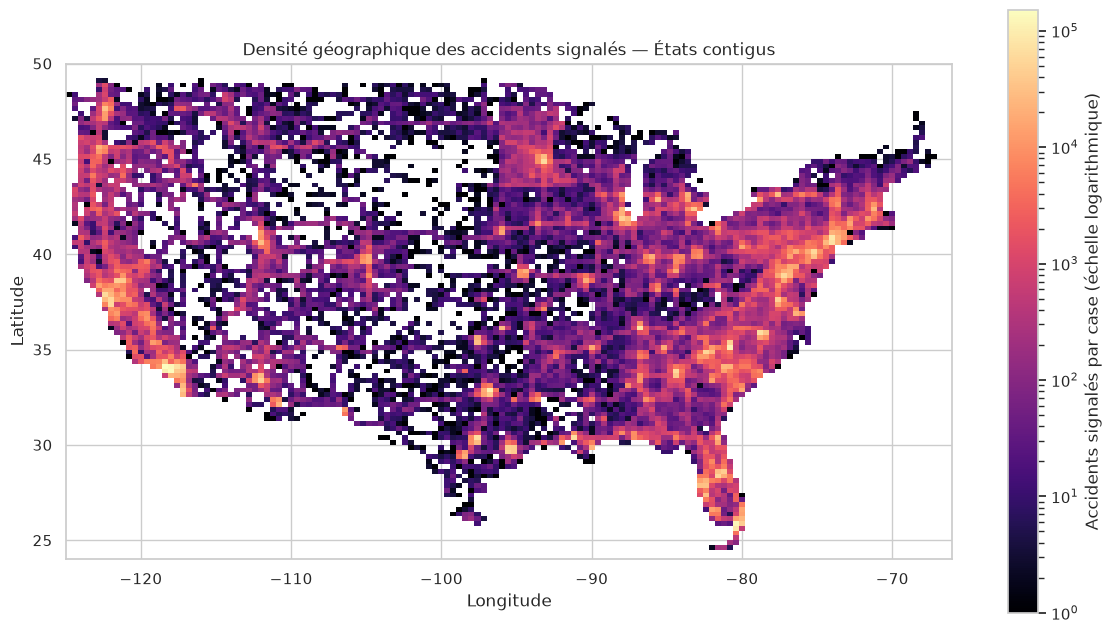

In [15]:
# Carte de densité : agrégats Spark sur tous les accidents du dataset, pas un affichage en échantillon.
# L'emprise cible les États contigus pour garder des cases lisibles ; Alaska et Hawaï restent inclus ailleurs dans l'analyse.
lon_min,lon_max,lat_min,lat_max=-125.,-66.,24.,50.
lon_step,lat_step=.4,.25
geo=(features.filter(F.col('Start_Lat').between(lat_min,lat_max)&F.col('Start_Lng').between(lon_min,lon_max))
     .groupBy(F.floor((F.col('Start_Lng')-lon_min)/lon_step).cast('int').alias('xb'),
              F.floor((F.col('Start_Lat')-lat_min)/lat_step).cast('int').alias('yb'))
     .agg(F.count('*').alias('accidents'))
     .toPandas())
print(f'{len(geo):,} cases géographiques occupées ; {int(geo.accidents.sum()):,} accidents agrégés dans le rectangle.')
heat=geo.pivot(index='yb',columns='xb',values='accidents').fillna(0).sort_index().sort_index(axis=1)
image=np.zeros((int(np.ceil((lat_max-lat_min)/lat_step)),int(np.ceil((lon_max-lon_min)/lon_step))))
image[heat.index.to_numpy()[:,None],heat.columns.to_numpy()[None,:]]=heat.to_numpy()
from matplotlib.colors import LogNorm
fig,ax=plt.subplots(figsize=(12,6.5))
mesh=ax.pcolormesh(lon_min+np.arange(image.shape[1]+1)*lon_step,
                   lat_min+np.arange(image.shape[0]+1)*lat_step,image,
                   shading='flat',cmap='magma',norm=LogNorm(vmin=1,vmax=max(2,image.max())))
fig.colorbar(mesh,ax=ax,label='Accidents signalés par case (échelle logarithmique)')
ax.set(xlim=(lon_min,lon_max),ylim=(lat_min,lat_max),xlabel='Longitude',ylabel='Latitude',
       title='Densité géographique des accidents signalés — États contigus')
ax.set_aspect(1/np.cos(np.deg2rad(38)))
plt.tight_layout();plt.show()

### Lire la carte avec prudence
Les cases ont une taille angulaire de 0,4° × 0,25° ; la couleur montre les **signalements observés** sur toute la période.
Le logarithme rend visibles les zones moins denses. Cette carte ne mesure ni le taux par habitant, ni le risque par kilomètre,
ni l'effet causal du lieu : la circulation et la couverture des capteurs varient entre États.

### Interprétation
La diagonale de la matrice normalisée donne le rappel par classe. Une accuracy élevée peut coexister avec un
faible rappel des niveaux rares ; les quatre scores par classe doivent être lus avec leurs effectifs.
Les différences 2022/2023 mélangent dérive de collecte, saisonnalité et évolution des accidents. Elles ne prouvent
pas à elles seules une causalité. Le test 2023 ne représente qu'un trimestre.

**Résultat mesuré :** Régression logistique — pondération modérée, macro-F1 **0.275**, accuracy **0.820**, sur **2,009,085 événements de test**. Référence majoritaire : macro-F1 **0.239**.

,imputed_month_sin,imputed_Traffic_Signal_num,imputed_Crossing_num,State_vector_CA,State_vector_AZ,imputed_hour_cos,imputed_month_cos,imputed_Start_Lng,State_vector_SC,imputed_Stop_num,State_vector_OR,State_vector_GA
Severity 1,0.440,0.228,0.140,0.020,0.154,-0.051,-0.132,-0.102,-0.062,0.019,0.072,-0.027
Severity 2,-0.257,0.068,0.081,0.092,-0.088,-0.026,0.119,-0.048,0.128,0.078,0.025,-0.104
Severity 3,-0.117,-0.211,-0.172,0.053,-0.071,-0.075,-0.001,0.019,0.002,-0.124,-0.123,0.044
Severity 4,-0.065,-0.085,-0.049,-0.165,0.005,0.152,0.014,0.130,-0.068,0.027,0.026,0.087


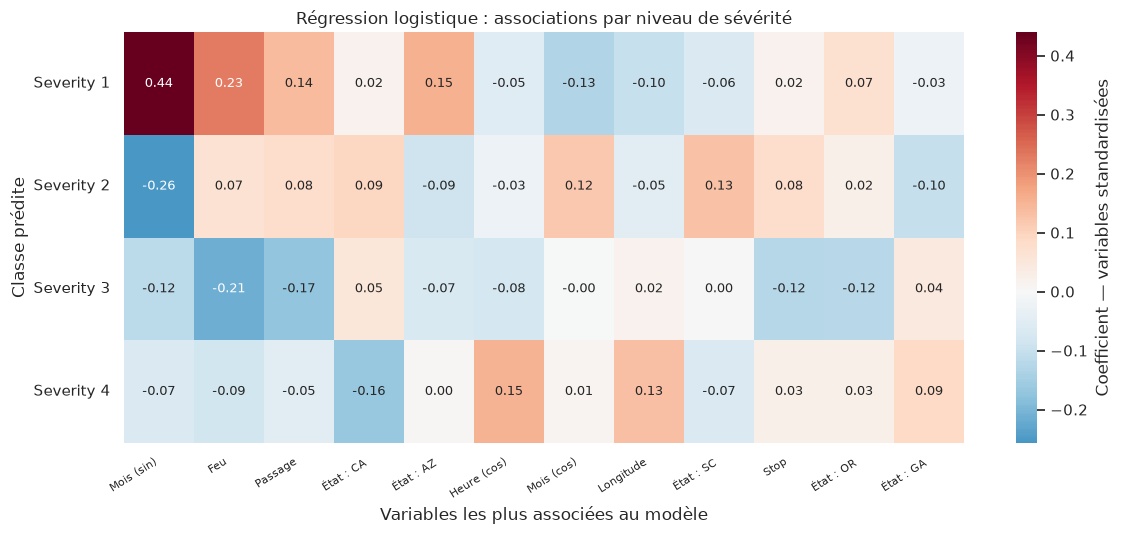

In [16]:
display(Markdown(f'**Résultat mesuré :** {best_name}, macro-F1 **{test_metrics["macro_f1"]:.3f}**, '
                f'accuracy **{test_metrics["accuracy"]:.3f}**, sur **{test_metrics["n"]:,} événements de test**. '
                f'Référence majoritaire : macro-F1 **{baseline_test["macro_f1"]:.3f}**.'))
# Une lecture des importances aide à discuter le modèle, sans les interpréter causalement.
classifier=final_model.stages[-1]
encoded=final_model.transform(fit_data.limit(1))
attrs=encoded.schema['assembled'].metadata['ml_attr']['attrs']
names={v['idx']:v['name'] for group in attrs.values() for v in group}
if hasattr(classifier,'featureImportances'):
    importance=pd.DataFrame({'variable':[names.get(i,str(i)) for i in range(classifier.numFeatures)],
                             'importance':classifier.featureImportances.toArray()}).sort_values('importance',ascending=False)
    display(importance.head(15))
    importance.head(15).sort_values('importance').plot.barh(x='variable',y='importance',legend=False,figsize=(9,5),color='#4c78a8')
    plt.title('Importances de la forêt — associatives, non causales');plt.tight_layout();plt.show()
elif hasattr(classifier,'coefficientMatrix'):
    coef=classifier.coefficientMatrix.toArray()
    by_feature=pd.DataFrame({'variable':[names.get(i,str(i)) for i in range(coef.shape[1])],
                             'importance':np.sqrt(np.mean(coef**2,axis=0))})
    selected=by_feature.nlargest(12,'importance')['variable'].tolist()
    indices=[next(i for i,name in names.items() if name==target) for target in selected]
    coefficient_view=pd.DataFrame(coef[:,indices],index=[f'Severity {i}' for i in [1,2,3,4]],columns=selected)
    display(coefficient_view.round(3))
    def concise_feature(name):
        if name.startswith('State_vector_'): return 'État : '+name.removeprefix('State_vector_')
        if name.startswith('Weather_Group_vector_'): return 'Météo : '+name.removeprefix('Weather_Group_vector_')
        return ({'imputed_hour_sin':'Heure (sin)','imputed_hour_cos':'Heure (cos)',
                 'imputed_weekday_sin':'Jour (sin)','imputed_weekday_cos':'Jour (cos)',
                 'imputed_month_sin':'Mois (sin)','imputed_month_cos':'Mois (cos)',
                 'imputed_Start_Lat':'Latitude','imputed_Start_Lng':'Longitude',
                 'imputed_Temperature_F':'Température','imputed_Humidity_pct':'Humidité',
                 'imputed_Pressure_in':'Pression','imputed_Visibility_mi':'Visibilité',
                 'imputed_Wind_Speed_mph':'Vitesse du vent','imputed_Precipitation_in':'Précipitations',
                 'imputed_Junction_num':'Carrefour','imputed_Traffic_Signal_num':'Feu',
                 'imputed_Crossing_num':'Passage','imputed_Stop_num':'Stop'}.get(name,name))
    coefficient_view.columns=[concise_feature(c) for c in coefficient_view.columns]
    fig,ax=plt.subplots(figsize=(12,5.5))
    sns.heatmap(coefficient_view,center=0,cmap='RdBu_r',annot=True,fmt='.2f',ax=ax,
                cbar_kws={'label':'Coefficient — variables standardisées'},annot_kws={'size':9})
    ax.set(xlabel='Variables les plus associées au modèle',ylabel='Classe prédite',
           title='Régression logistique : associations par niveau de sévérité')
    ax.set_yticklabels([f'Severity {i}' for i in [1,2,3,4]],rotation=0)
    ax.set_xticklabels(coefficient_view.columns,rotation=32,ha='right',fontsize=8)
    plt.tight_layout();plt.show()

## 9. Sauvegarde, rechargement et prédiction batch
Le modèle est exporté sur le système local pour l'API, indépendamment de la disponibilité ultérieure de HDFS.
Le pipeline Spark sauvegarde les médianes, les encodages et le classifieur. Les transformations déterministes
restent dans le module partagé. Nous vérifions que les prédictions ne changent pas après rechargement.

In [17]:
model_dir=ROOT/'artifacts/accidents/pipeline'
final_model.write().overwrite().save(local_uri(model_dir))
save_json({'model':best_name,'target':'Severity','label_mapping':{'0':1,'1':2,'2':3,'3':4},
           'numeric':NUMERIC,'categorical':CATEGORICAL,'raw_features':RAW_FEATURES,'train_fraction':TRAIN_FRACTION,
           'fit_rows':fit_rows,'selected_weight_power':selected_power,'test_metrics':test_metrics,'spark_version':spark.version,
           'weather_max_age_hours':2,'seed':SEED,'weights':final_weights},ROOT/'artifacts/accidents/metadata.json')
loaded=PipelineModel.load(local_uri(model_dir))
probe=test.orderBy('ID').limit(8).cache()
a=final_model.transform(probe).select('ID','prediction').orderBy('ID').collect()
b=loaded.transform(probe).select('ID','prediction').orderBy('ID').collect()
assert a==b
print('Prédictions identiques après rechargement.')
# Un lot distribué peut être produit directement dans HDFS.
predictions.select('ID',(F.col('prediction')+1).alias('Severity_predicted')).write.mode('overwrite').parquet(HDFS_BASE+'/test_predictions')
print('Prédictions batch enregistrées dans HDFS.')
probe.unpersist()

Prédictions identiques après rechargement.


Prédictions batch enregistrées dans HDFS.


DataFrame[ID: string, label: double, Start_Lat: double, Start_Lng: double, Temperature_F: double, Humidity_pct: double, Pressure_in: double, Visibility_mi: double, Wind_Speed_mph: double, Precipitation_in: double, hour_sin: double, hour_cos: double, weekday_sin: double, weekday_cos: double, month_sin: double, month_cos: double, Junction_num: double, Traffic_Signal_num: double, Crossing_num: double, Stop_num: double, State: string, Weather_Group: string, year: int]

## 10. Déploiement de l'API locale et vérification du contrat
L'API reçoit les variables brutes, applique exactement `engineer`, puis le pipeline sauvegardé.
La validation contrôle les domaines des valeurs et la taille du lot. Les catégories inconnues sont acceptées
par l'encodage appris. L'ordre des requêtes est conservé grâce à un identifiant explicite.
Le serveur Spark reste chargé entre les appels : ce service convient à une démonstration ou des petits lots,
pas à une exigence de latence temps réel stricte.

In [18]:
# Exemple issu du jeu de test avec coordonnées et horodatage valides.
source=raw.filter(F.col('year')>=2022).filter(F.col('Start_Time').isNotNull()).select(*RAW_FEATURES).first().asDict()
from api.accidents_api import MAPPING,Accident,to_raw
numeric_keys={'latitude','longitude','temperature_f','humidity_pct','pressure_in','visibility_mi','wind_speed_mph','precipitation_in'}
bool_keys={'junction','traffic_signal','crossing','stop'}
item={}
for api_name,csv_name in MAPPING.items():
    value=source.get(csv_name)
    if api_name in numeric_keys: value=None if value is None else float(value)
    elif api_name in bool_keys: value=None if value is None else value.lower()=='true'
    item[api_name]=value
# Pydantic garantit que l'exemple respecte le même contrat que les requêtes futures.
validated=Accident(**item)
payload={'accidents':[validated.model_dump(mode='json')]}
save_json(payload,ROOT/'api/example_accidents.json')
from tp3.accidents import raw_schema
expected_row=loaded.transform(engineer(spark.createDataFrame([to_raw(validated)],schema=raw_schema()))).select('prediction','probability').first()
expected={'severity':int(expected_row.prediction)+1,'scores':list(expected_row.probability)}
fit_data.unpersist();predictions.unpersist()
spark.stop()  # Libération des ressources d'analyse avant de tester le service.

In [19]:
from starlette.testclient import TestClient
from api.accidents_api import app
with TestClient(app) as client:
    health=client.get('/health');assert health.status_code==200
    response=client.post('/predict',json=payload)
    assert response.status_code==200,response.text
    result=response.json()['predictions'][0]
    assert result['severity']==expected['severity']
    np.testing.assert_allclose(list(result['scores'].values()),expected['scores'],atol=1e-6)
    assert client.post('/predict',json={'accidents':[]}).status_code==422
    invalid={'accidents':[dict(payload['accidents'][0],latitude=999)]}
    assert client.post('/predict',json=invalid).status_code==422
    print('Health :',health.json())
    print('Prédiction API :',response.json())
print('API : cohérence avec le notebook et validation des entrées vérifiées.')

/tmp/ipykernel_768521/3271565423.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient


Health : {'status': 'ok', 'model': 'Régression logistique — pondération modérée', 'task': 'classification', 'classes': [1, 2, 3, 4]}
Prédiction API : {'model': 'Régression logistique — pondération modérée', 'predictions': [{'severity': 2, 'scores': {'1': 0.029025, '2': 0.648128, '3': 0.278922, '4': 0.043926}}], 'score_note': 'Scores du modèle pondéré ; probabilités non calibrées.'}


API : cohérence avec le notebook et validation des entrées vérifiées.


### Lancer le service
Depuis la racine du TP3 :
```bash
bash scripts/start_api.sh accidents
```
Documentation interactive : **http://127.0.0.1:8002/docs**.
Dans un second terminal :
```bash
curl -s http://127.0.0.1:8002/predict -H 'Content-Type: application/json' --data-binary @api/example_accidents.json
```
Arrêt avec `Ctrl+C`. HDFS n'est pas requis par l'API une fois le modèle exporté.

## 11. Bilan, limites et reproductibilité
- Ingestion, exploration et transformation distribuées sur le dataset complet ; entraînement explicitement échantillonné.
- Comparaison de modèles classiques, métriques adaptées au déséquilibre et test dans le futur du train.
- Le split temporel ne garantit pas que deux signalements proches ne décrivent pas un même événement : seul l'ID a été dédupliqué.
- Les variables météo sont contrôlées temporellement ; le fichier ne documente pas tous les délais de collecte des autres champs.
- Pas de mesure de blessures, de causalité ni de probabilité d'accident dans une population sans accident.
- Les temps mesurés dépendent du matériel, du cache et de la charge ; aucune accélération multi-machines n'est revendiquée.

### Sources et inspirations
- [Dataset US Accidents, version 13](https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents) — CC BY-NC-SA 4.0, usage académique.
- Moosavi et al., [A Countrywide Traffic Accident Dataset](https://arxiv.org/abs/1906.05409), 2019.
- Moosavi et al., [Accident Risk Prediction based on Heterogeneous Sparse Data](https://arxiv.org/abs/1909.09638), ACM SIGSPATIAL 2019.
- [Spark : classification et régression](https://spark.apache.org/docs/latest/ml-classification-regression.html).
- [Spark : pipelines ML](https://spark.apache.org/docs/latest/ml-pipeline.html).
- Inspiration pédagogique locale : `../TP 2/etude_accidents_pyspark.ipynb` (organisation EDA, agrégations Spark et lecture critique).
Ce TP2 utilise un autre dataset ; aucun résultat numérique n'en est repris.